# GMM

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import ndimage as ndi
from scipy.stats import norm

from sklearn.mixture import GaussianMixture
from skimage import io, filters, morphology, measure
from skimage.color import rgb2gray

In [5]:
# =====================================================
# 1. PARAMETERS
# =====================================================

image_paths = [
    "img1.tif",
    "img2.tif",
    "img3.tif",
    "img4.tif"
]

output_dir = Path("GMM_segmentation_results")
output_dir.mkdir(parents=True, exist_ok=True)

# Preprocessing
sigma = 1

# Segmentation
min_area = 20
connectivity = 2

# GMM parameters
n_components = 3
threshold_factor = 1.15
random_state = 42
n_init = 10
max_iter = 300
max_fit_pixels = 100000  # 512x512 image 262144

# Visualization
show_plots = True


Processing: img1


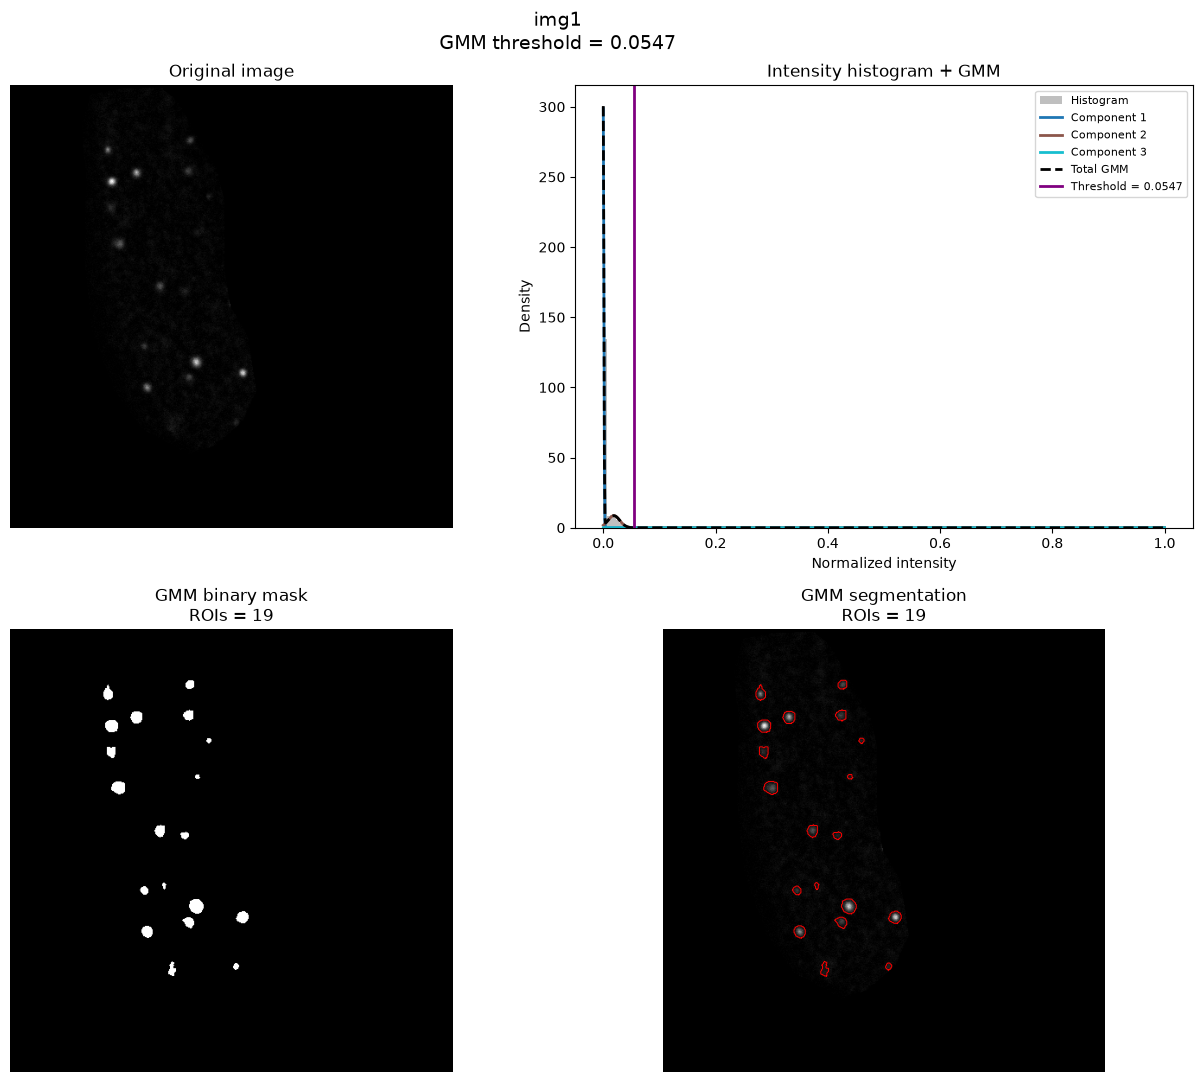


Processing: img2


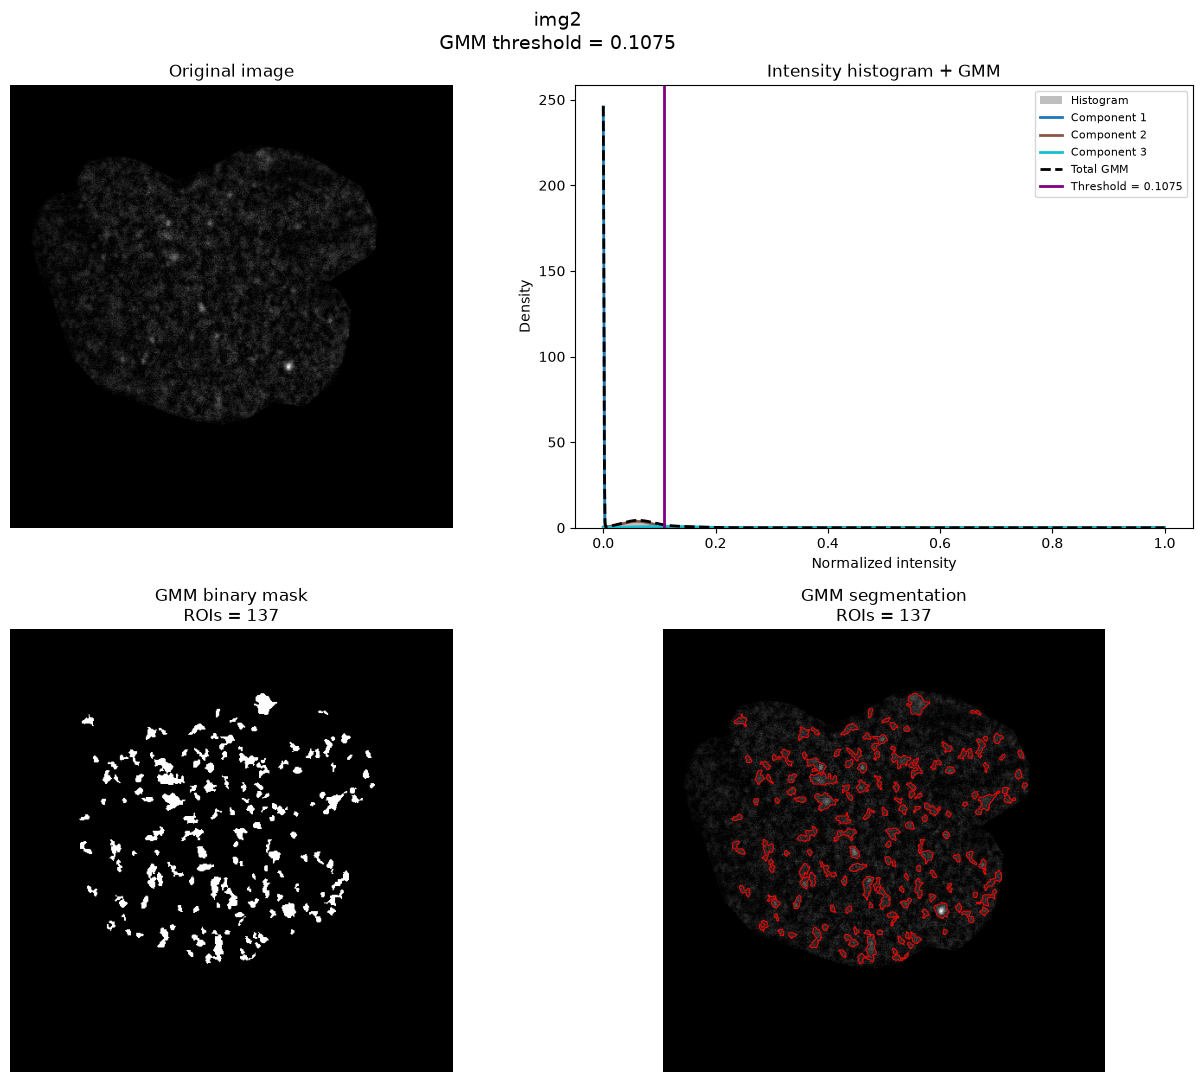


Processing: img3


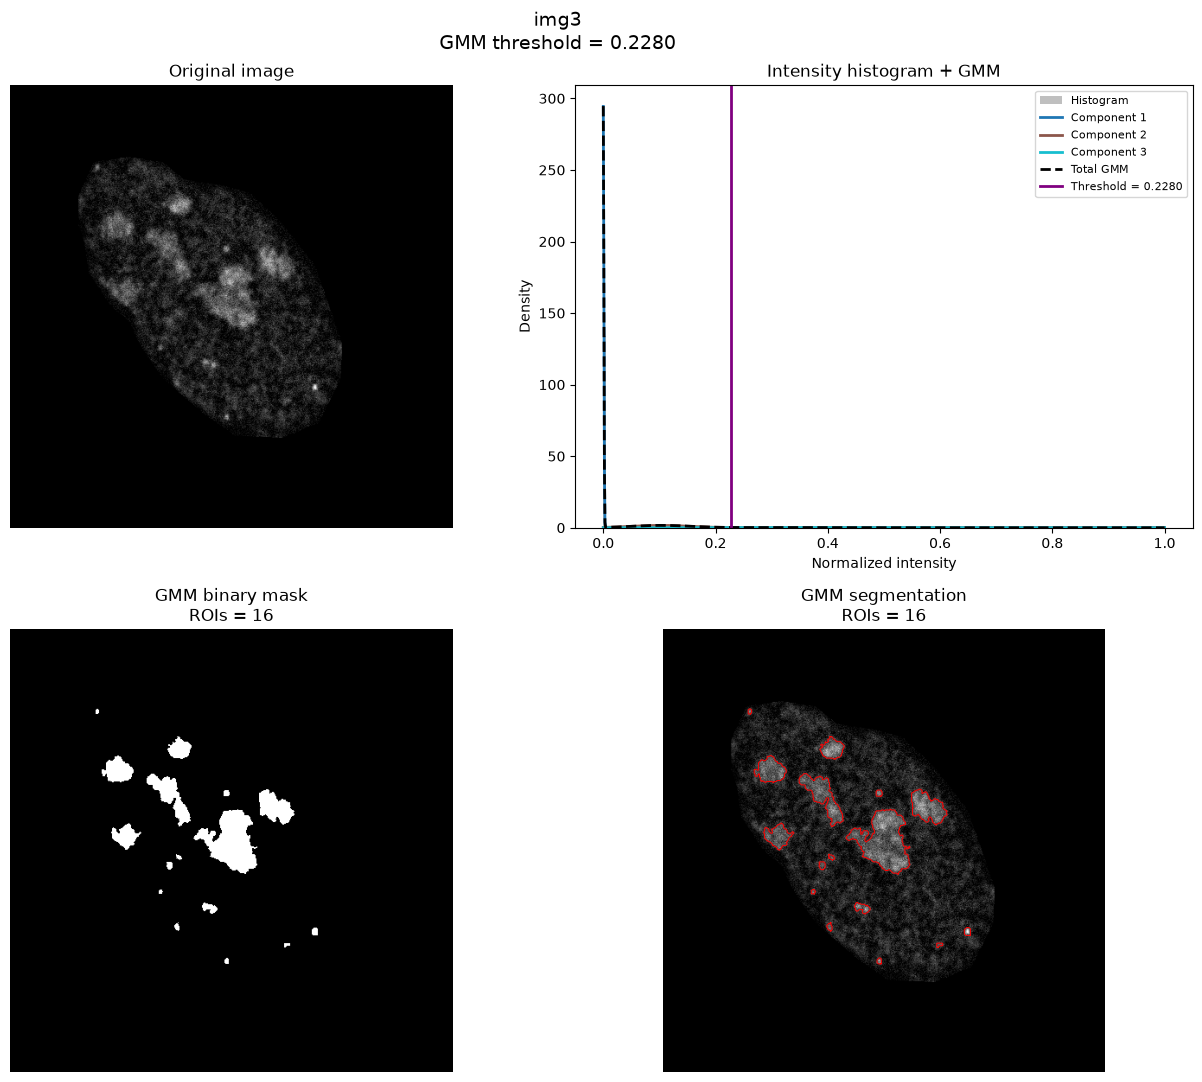


Processing: img4


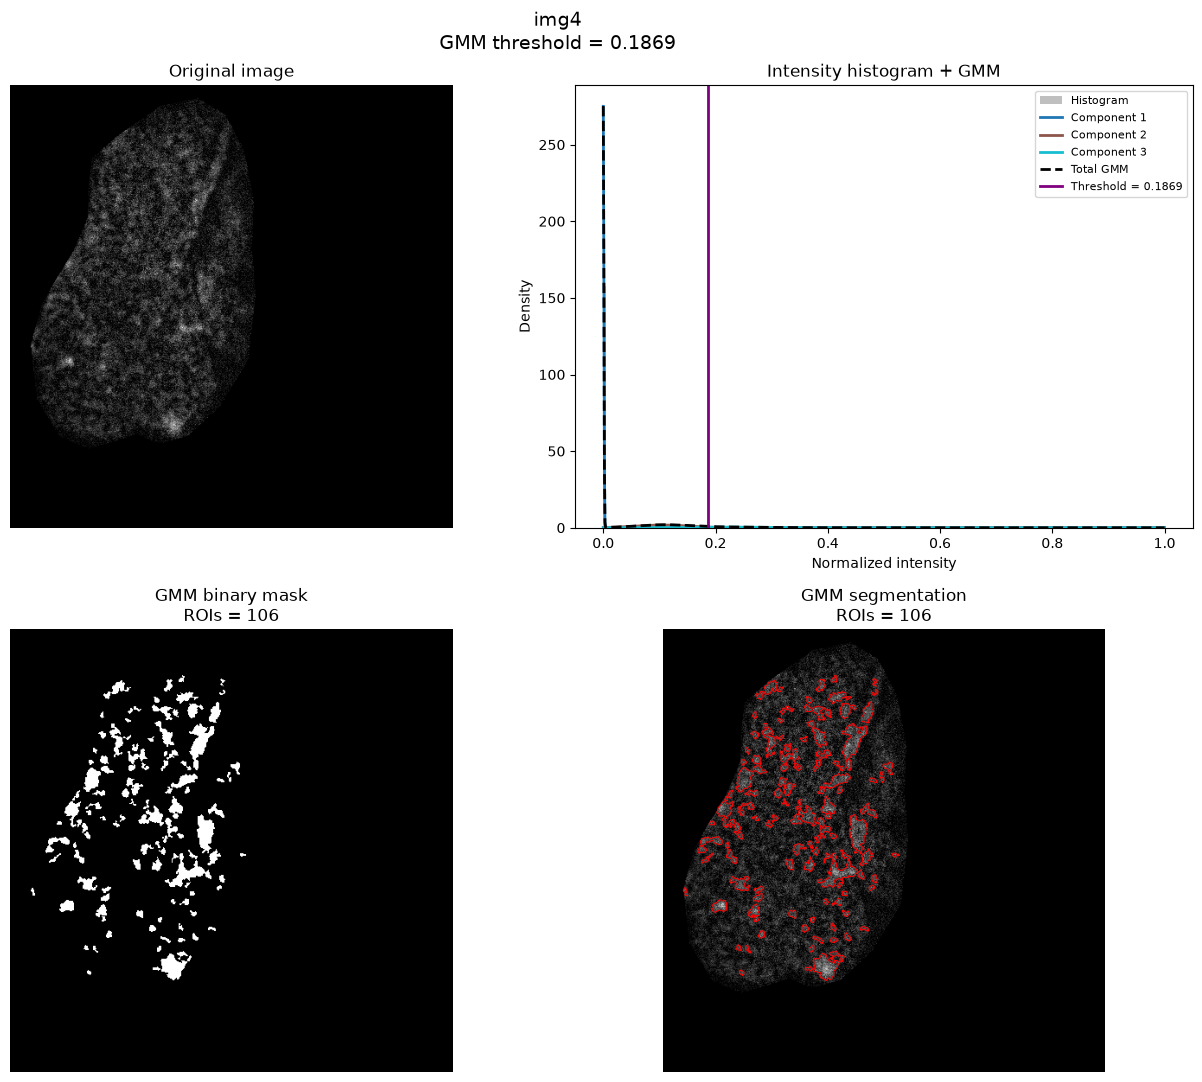


GMM SEGMENTATION RESULTS:
image  GMM_threshold  n_ROIs  mean_1  mean_2  mean_3  weight_1  weight_2  weight_3
 img1         0.0547      19     0.0  0.0188  0.1387    0.7598    0.2286    0.0115
 img2         0.1075     137     0.0  0.0602  0.1090    0.6239    0.2602    0.1158
 img3         0.2280      16     0.0  0.1030  0.3241    0.7447    0.2155    0.0397
 img4         0.1869     106     0.0  0.1055  0.2103    0.6972    0.2139    0.0889


In [6]:
# =====================================================
# 2. LOAD AND NORMALIZE IMAGE
# =====================================================

def load_image(image_path):

    image = io.imread(image_path)

    if image.ndim == 3 and image.shape[-1] in (3, 4):
        image = rgb2gray(image[..., :3])

    if image.ndim != 2:
        raise ValueError(
            f"Expected 2D image, got {image.shape}"
        )

    image = image.astype(np.float64)

    if not np.isfinite(image).all():
        raise ValueError("Image contains NaN or Inf")

    imin = image.min()
    imax = image.max()

    if imax <= imin:
        raise ValueError("Image has constant intensity")

    image = (image - imin) / (imax - imin)

    return image


# =====================================================
# 3. FIT GAUSSIAN MIXTURE MODEL
# =====================================================

def fit_gmm(image):

    pixels = image.reshape(-1, 1)

    rng = np.random.default_rng(random_state)

    if len(pixels) > max_fit_pixels:

        indices = rng.choice(
            len(pixels),
            size=max_fit_pixels,
            replace=False
        )

        fit_pixels = pixels[indices]

    else:
        fit_pixels = pixels

    gmm = GaussianMixture(
        n_components=n_components,
        covariance_type="full",
        random_state=random_state,
        n_init=n_init,
        max_iter=max_iter,
        reg_covar=1e-6
    )

    gmm.fit(fit_pixels)

    return gmm


# =====================================================
# 4. EXTRACT GMM PARAMETERS
# =====================================================

def get_gmm_parameters(gmm):

    means = gmm.means_.flatten()
    stds = np.sqrt(gmm.covariances_.reshape(-1))
    weights = gmm.weights_

    order = np.argsort(means)

    return (
        means[order],
        stds[order],
        weights[order]
    )


# =====================================================
# 5. CALCULATE GMM THRESHOLD
# =====================================================

def find_gmm_threshold(gmm, means, grid_size=10000):
    """
    Find the first intensity above the middle
    Gaussian mean where the brightest component
    has the highest posterior probability.
    """

    intensity_grid = np.linspace(0, 1, grid_size)

    probabilities = gmm.predict_proba(
        intensity_grid.reshape(-1, 1)
    )

    brightest_component = np.argmax(
        gmm.means_.flatten()
    )

    predicted_components = np.argmax(
        probabilities,
        axis=1
    )

    candidate_indices = np.where(
        (intensity_grid >= means[1])
        & (predicted_components == brightest_component)
    )[0]

    if len(candidate_indices) == 0:
        raise ValueError(
            "No high-intensity GMM decision region found."
        )

    return intensity_grid[candidate_indices[0]]


# =====================================================
# 6. SEGMENTATION
# =====================================================

def segment_image(smooth, threshold):

    # Threshold
    mask = smooth > threshold

    # Fill holes
    mask = ndi.binary_fill_holes(mask)

    # Remove small objects
    mask = morphology.remove_small_objects(
        mask,
        min_size=min_area,
        connectivity=connectivity
    )

    # Connected Components
    labels = measure.label(
        mask,
        connectivity=connectivity
    )

    return mask, labels


# =====================================================
# 7. DRAW ROI CONTOURS
# =====================================================

def draw_contours(ax, image, labels):

    ax.imshow(image, cmap="gray")

    for region in measure.regionprops(labels):

        roi_mask = labels == region.label

        contours = measure.find_contours(
            np.pad(
                roi_mask.astype(float),
                1,
                mode="constant"
            ),
            level=0.5
        )

        for contour in contours:

            ax.plot(
                contour[:, 1] - 1,
                contour[:, 0] - 1,
                color="red",
                linewidth=0.7
            )

    ax.axis("off")


# =====================================================
# 8. PROCESS ONE IMAGE
# =====================================================

def process_image_gmm(
    image_path,
    threshold_factor = 1,
    plot=True,
    save_path=None
):

    image_name = Path(image_path).stem

    # Load image
    image = load_image(image_path)

    # Gaussian smoothing
    smooth = filters.gaussian(
        image,
        sigma=sigma
    )

    # Fit GMM
    gmm = fit_gmm(smooth)

    # Extract components
    means, stds, weights = get_gmm_parameters(gmm)

    # Find threshold
    T_gmm = find_gmm_threshold(
        gmm,
        means
    )
    
    T_adjusted = T_gmm * threshold_factor

    # Segment
    mask, labels = segment_image(
        smooth,
        T_adjusted
    )

    n_rois = int(labels.max())

    # -----------------------------------------------
    # GMM DISTRIBUTIONS
    # -----------------------------------------------

    x = np.linspace(0, 1, 1000)

    component_densities = []

    for mean, std, weight in zip(
        means, stds, weights
    ):

        density = weight * norm.pdf(
            x,
            loc=mean,
            scale=std
        )

        component_densities.append(density)

    total_density = np.sum(
        component_densities,
        axis=0
    )

    # -----------------------------------------------
    # VISUALIZATION
    # -----------------------------------------------

    if plot or save_path is not None:

        fig, axes = plt.subplots(
            2, 2,
            figsize=(13, 11)
        )

        # Original image
        axes[0, 0].imshow(
            image,
            cmap="gray"
        )
        axes[0, 0].set_title("Original image")
        axes[0, 0].axis("off")

        # Histogram + GMM
        axes[0, 1].hist(
            smooth.ravel(),
            bins=150,
            density=True,
            color="gray",
            alpha=0.5,
            label="Histogram"
        )

        colors = plt.cm.tab10(np.linspace(0, 1, n_components))

        for i, density in enumerate(component_densities):

            axes[0, 1].plot(
                x,
                density,
                color=colors[i],
                linewidth=2,
                label=f"Component {i+1}"
            )

        axes[0, 1].plot(
            x,
            total_density,
            color="black",
            linestyle="--",
            linewidth=2,
            label="Total GMM"
        )

        axes[0, 1].axvline(
            T_gmm,
            color="purple",
            linewidth=2,
            label=f"Threshold = {T_gmm:.4f}"
        )

        axes[0, 1].set_title(
            "Intensity histogram + GMM"
        )
        axes[0, 1].set_xlabel(
            "Normalized intensity"
        )
        axes[0, 1].set_ylabel("Density")
        axes[0, 1].legend(fontsize=8)

        # Binary mask
        axes[1, 0].imshow(
            mask,
            cmap="gray"
        )
        axes[1, 0].set_title(
            f"GMM binary mask\nROIs = {n_rois}"
        )
        axes[1, 0].axis("off")

        # Segmented ROIs
        draw_contours(
            axes[1, 1],
            image,
            labels
        )
        axes[1, 1].set_title(
            f"GMM segmentation\nROIs = {n_rois}"
        )

        plt.suptitle(
            f"{image_name}\nGMM threshold = {T_gmm:.4f}",
            fontsize=14
        )

        plt.tight_layout()

        if save_path is not None:
            plt.savefig(
                save_path,
                dpi=200,
                bbox_inches="tight"
            )

        if plot:
            plt.show()

        plt.close(fig)

    return {
        "image": image_name,
        "threshold": T_gmm,
        "means": means,
        "stds": stds,
        "weights": weights,
        "n_rois": n_rois,
        "mask": mask,
        "labels": labels
    }


# =====================================================
# 9. PROCESS ALL FOUR IMAGES
# =====================================================

results = {}
summary = []

for image_path in image_paths:

    image_name = Path(image_path).stem

    print(f"\nProcessing: {image_name}")

    result = process_image_gmm(
        image_path,
        threshold_factor=threshold_factor,
        plot=show_plots,
        save_path=output_dir / f"{image_name}_GMM.png"
    )

    results[image_name] = result

    summary.append({
        "image": image_name,
        "GMM_threshold": result["threshold"],
        "n_ROIs": result["n_rois"],
        "mean_1": result["means"][0],
        "mean_2": result["means"][1],
        "mean_3": result["means"][2],
        "weight_1": result["weights"][0],
        "weight_2": result["weights"][1],
        "weight_3": result["weights"][2]
    })

    # Save binary mask
    io.imsave(
        output_dir / f"{image_name}_GMM_mask.tif",
        (result["mask"] * 255).astype(np.uint8),
        check_contrast=False
    )

    # Save labeled image
    io.imsave(
        output_dir / f"{image_name}_GMM_labels.tif",
        result["labels"].astype(np.int32),
        check_contrast=False
    )


# =====================================================
# 10. SUMMARY
# =====================================================

summary_df = pd.DataFrame(summary)

print("\nGMM SEGMENTATION RESULTS:")
print(summary_df.round(4).to_string(index=False))

summary_df.to_csv(
    output_dir / "GMM_summary.csv",
    index=False
)
